2. Tự viết K‐Means

In [3]:
# -*- coding: utf-8 -*-
"""Bước 1: tự viết K-Means bằng numpy, chạy trên bảy điểm của slide.

Chú thích viết tiếng Việt có dấu, phần in ra màn hình viết không dấu.
"""

import numpy as np
from sklearn.cluster import KMeans

P = np.array([[1.0, 1.0], [1.5, 2.0], [3.0, 4.0], [5.0, 7.0],
              [3.5, 5.0], [4.5, 5.0], [3.5, 4.5]])
TEN = ["A", "B", "C", "D", "E", "F", "G"]


def k_means(X, tam, so_vong_toi_da=10):
    """K-Means don gian: gan diem vào tam gan nhat roi doi tam."""
    for vong in range(1, so_vong_toi_da + 1):
        # Bước gán: khoảng cách từ mỗi điểm tới mỗi tâm
        kc = np.sqrt(((X[:, None, :] - tam[None, :, :]) ** 2).sum(axis=2))
        nhan = kc.argmin(axis=1)
        print(f"Vong {vong}: tam = {np.round(tam, 2).tolist()}")
        for k in range(len(tam)):
            ds = [TEN[i] for i in range(len(X)) if nhan[i] == k]
            print(f"  cum {k + 1}: {', '.join(ds)}")
        # Bước dời tâm: trung bình các điểm trong mỗi cụm
        tam_moi = np.array([X[nhan == k].mean(axis=0)
                            for k in range(len(tam))])
        if np.allclose(tam_moi, tam):
            print("  Tam khong doi nua, dung.")
            return tam, nhan
        tam = tam_moi
    return tam, nhan


# Khởi tạo cố ý tệ: hai tâm là A và B, nằm sát nhau
tam, nhan = k_means(P, P[[0, 1]].copy())
print()

# Tính inertia: tổng bình phương khoảng cách tới tâm cụm của mình
inertia = ((P - tam[nhan]) ** 2).sum()
print(f"Inertia tu tinh: {inertia:.4f}")

# So với scikit-learn, cho cùng tâm ban đầu
km = KMeans(n_clusters=2, init=P[[0, 1]], n_init=1).fit(P)
print(f"Inertia cua scikit-learn: {km.inertia_:.4f}")
print("Tam cua scikit-learn:", np.round(km.cluster_centers_, 2).tolist())

Vong 1: tam = [[1.0, 1.0], [1.5, 2.0]]
  cum 1: A
  cum 2: B, C, D, E, F, G
Vong 2: tam = [[1.0, 1.0], [3.5, 4.58]]
  cum 1: A, B
  cum 2: C, D, E, F, G
Vong 3: tam = [[1.25, 1.5], [3.9, 5.1]]
  cum 1: A, B
  cum 2: C, D, E, F, G
  Tam khong doi nua, dung.

Inertia tu tinh: 8.5250
Inertia cua scikit-learn: 8.5250
Tam cua scikit-learn: [[1.25, 1.5], [3.9, 5.1]]


3. Phân khúc khách hàng

In [4]:
# -*- coding: utf-8 -*-
"""Bước 2: phân khúc khách hàng bằng K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
print("Kich thuoc bang:", df.shape)
print(df.describe().round(1).to_string())
print()

X = df[["thu_nhap", "diem_chi_tieu"]]
sc = StandardScaler().fit(X)
Xs = sc.transform(X)

km = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
df["cum"] = km.labels_

# Tâm cụm đang ở thang đã chuẩn hoá, đổi ngược về đơn vị gốc để đọc
tam = pd.DataFrame(sc.inverse_transform(km.cluster_centers_),
                   columns=["thu_nhap", "diem_chi_tieu"])
tam["so_khach"] = np.bincount(km.labels_)
tam["tuoi_tb"] = df.groupby("cum")["tuoi"].mean()
print("Tam cum, don vi goc:")
print(tam.round(1).to_string())
print()

print(f"Inertia: {km.inertia_:.2f}")
print()

# Khách mới: chuẩn hoá bằng đúng bộ chuẩn hoá cũ rồi tìm tâm gần nhất
moi = pd.DataFrame({"thu_nhap": [29.0, 9.0],
                    "diem_chi_tieu": [85, 75]})
cum_moi = km.predict(sc.transform(moi))
for i in range(len(moi)):
    print(f"Khach moi {i + 1}: thu nhap {moi.iloc[i, 0]},"
          f" chi tieu {moi.iloc[i, 1]} -> cum {cum_moi[i]}")

Kich thuoc bang: (210, 3)
        tuoi  thu_nhap  diem_chi_tieu
count  210.0     210.0          210.0
mean    37.6      18.5           49.9
std     10.3       9.8           26.8
min     18.0       3.0            7.0
25%     30.0       8.8           22.0
50%     39.0      17.4           49.0
75%     46.0      28.6           77.0
max     62.0      35.5           99.0

Tam cum, don vi goc:
   thu_nhap  diem_chi_tieu  so_khach  tuoi_tb
0       7.5           80.2        35     24.9
1      30.1           20.0        35     42.9
2      17.4           49.3        60     40.4
3       8.0           18.9        40     44.9
4      30.2           81.5        40     32.6

Inertia: 23.02

Khach moi 1: thu nhap 29.0, chi tieu 85 -> cum 4
Khach moi 2: thu nhap 9.0, chi tieu 75 -> cum 0


4. Chọn số cụm K

In [5]:
# -*- coding: utf-8 -*-
"""Bước 3: chọn số cụm K bằng khuỷu tay và chỉ số silhouette."""

import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
Xs = StandardScaler().fit_transform(df[["thu_nhap", "diem_chi_tieu"]])

print("  K    inertia   giam so voi K-1   silhouette")
truoc = None
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(Xs)
    giam = "" if truoc is None else f"{truoc - km.inertia_:8.1f}"
    # Silhouette cần ít nhất hai cụm
    sil = "" if k == 1 else f"{silhouette_score(Xs, km.labels_):.3f}"
    print(f" {k:2d}   {km.inertia_:7.1f}   {giam:>15s}   {sil:>10s}")
    truoc = km.inertia_

  K    inertia   giam so voi K-1   silhouette
  1     420.0                               
  2     250.4             169.6        0.430
  3     152.5              97.9        0.522
  4      73.8              78.8        0.626
  5      23.0              50.7        0.723
  6      20.9               2.1        0.651
  7      19.0               1.9        0.541
  8      17.4               1.6        0.454
  9      15.9               1.5        0.471
 10      14.4               1.4        0.425


5. Ba cái bẫy của K‐Means

In [6]:
# -*- coding: utf-8 -*-
"""Bước 4: ba cái bẫy của K-Means."""

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("data/khach_hang.csv")
X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Bẫy 1: thu nhập ghi bằng nghìn đồng, không chuẩn hoá
X_nghin = X.copy()
X_nghin["thu_nhap"] = X_nghin["thu_nhap"] * 1000
km_tho = KMeans(n_clusters=5, n_init=10, random_state=0).fit(X_nghin)
tam_tho = km_tho.cluster_centers_.copy()
tam_tho[:, 0] = tam_tho[:, 0] / 1000          # đổi lại triệu đồng để dễ đọc
print("Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):")
for t in tam_tho[np.argsort(tam_tho[:, 0])]:
    print(f"  ({t[0]:5.1f}, {t[1]:5.1f})")
print()

# Bẫy 2: mỗi lần chỉ khởi tạo ngẫu nhiên một lần
ket = []
for rs in range(20):
    km = KMeans(n_clusters=5, init="random", n_init=1,
                random_state=rs).fit(Xs)
    ket.append(round(km.inertia_, 1))
print("Bay 2: inertia cua 20 lan khoi tao ngau nhien:")
ket = sorted(ket)
print(" ", ket[:10])
print(" ", ket[10:])
tot = KMeans(n_clusters=5, n_init=10, random_state=0).fit(Xs)
print(f"  Voi n_init=10: inertia {tot.inertia_:.1f}")
print()

# Bẫy 3: cụm không tròn, dữ liệu hai vầng trăng
tr = pd.read_csv("data/hai_vang_trang.csv")
km_tr = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan = km_tr.fit_predict(tr[["x1", "x2"]])
khop = (nhan == tr["nhan"]).mean()
# Số thứ tự cụm có thể ngược với nhãn thật, nên lấy cách khớp tốt hơn
print(f"Bay 3: hai vang trang, ty le khop nhan that "
      f"{max(khop, 1 - khop):.4f}")

Bay 1: khong chuan hoa, tam cum (thu nhap trieu, chi tieu):
  (  6.1,  52.5)
  (  9.6,  41.9)
  ( 17.4,  49.8)
  ( 27.8,  52.9)
  ( 31.9,  52.4)

Bay 2: inertia cua 20 lan khoi tao ngau nhien:
  [23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0, 23.0]
  [72.4, 73.6, 73.7, 73.7, 84.0, 84.2, 84.2, 116.6, 117.4, 118.2]
  Voi n_init=10: inertia 23.0

Bay 3: hai vang trang, ty le khop nhan that 0.7500


6. Nén màu ảnh

In [7]:
# -*- coding: utf-8 -*-
"""Bước 5: nén màu một bức ảnh bằng K-Means."""

import numpy as np
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

anh = load_sample_image("china.jpg")          # ảnh có sẵn trong scikit-learn
cao, rong, _ = anh.shape
diem = anh.reshape(-1, 3) / 255.0             # mỗi dòng là một điểm ảnh RGB
so_mau = len(np.unique(anh.reshape(-1, 3), axis=0))
print(f"Anh {cao} x {rong}, co {cao * rong} diem anh, {so_mau} mau")
print()

# Học trên 5000 điểm ảnh rút ngẫu nhiên cho nhanh, rồi gán cho mọi điểm
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

print("  K   so bit moi diem    nho hon   sai lech trung binh")
for k in [4, 16, 64]:
    km = KMeans(n_clusters=k, n_init=4, random_state=0).fit(mau)
    nhan = km.predict(diem)
    moi = km.cluster_centers_[nhan]
    bit = int(np.ceil(np.log2(k)))
    sai = np.abs(moi - diem).mean() * 255
    print(f"  {k:2d}        {bit}           {24 / bit:4.1f} lan"
          f"     {sai:5.2f} muc sang")

Anh 427 x 640, co 273280 diem anh, 96615 mau

  K   so bit moi diem    nho hon   sai lech trung binh
   4        2           12.0 lan     17.41 muc sang
  16        4            6.0 lan      7.97 muc sang
  64        6            4.0 lan      4.54 muc sang


7. bài tập

Bài 1

Silhouette trung bình tự tính: 0.7227055107668372
Silhouette sklearn: 0.7227055107668373

Khách hàng có Silhouette nhỏ nhất:
tuoi             38.0
thu_nhap         25.4
diem_chi_tieu    41.0
Name: 113, dtype: float64
Giá trị Silhouette: 0.028570617627034552


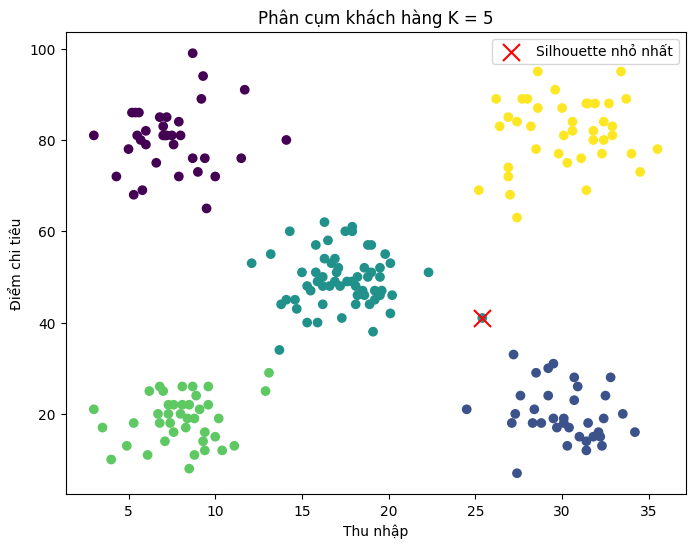

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

def silhouette_mot_diem(X, nhan, i):
    cum_i = nhan[i]

    # Tính khoảng cách trung bình đến các điểm cùng cụm
    chi_so = np.where(nhan == cum_i)[0]
    chi_so = chi_so[chi_so != i]

    if len(chi_so) == 0:
        return 0

    a = np.mean(np.linalg.norm(X[chi_so] - X[i], axis=1))

    # Tính khoảng cách trung bình đến cụm gần nhất khác
    b = np.inf

    for k in np.unique(nhan):
        if k != cum_i:
            diem_cum = X[nhan == k]
            kc = np.mean(np.linalg.norm(diem_cum - X[i], axis=1))
            b = min(b, kc)

    s = (b - a) / max(a, b)

    return s


# Đọc dữ liệu
df = pd.read_csv("data/khach_hang.csv")

X = df[["thu_nhap", "diem_chi_tieu"]]
Xs = StandardScaler().fit_transform(X)

# Phân cụm K = 5
km = KMeans(n_clusters=5, n_init=10, random_state=0)
nhan = km.fit_predict(Xs)

# Tính Silhouette cho từng khách hàng
sil = np.array([
    silhouette_mot_diem(Xs, nhan, i)
    for i in range(len(Xs))
])

print("Silhouette trung bình tự tính:", sil.mean())
print("Silhouette sklearn:", silhouette_score(Xs, nhan))

# Tìm khách hàng có Silhouette nhỏ nhất
i_min = np.argmin(sil)

print("\nKhách hàng có Silhouette nhỏ nhất:")
print(df.iloc[i_min])
print("Giá trị Silhouette:", sil[i_min])

# Vẽ biểu đồ và đánh dấu khách hàng đó
plt.figure(figsize=(8, 6))

plt.scatter(
    df["thu_nhap"],
    df["diem_chi_tieu"],
    c=nhan,
    cmap="viridis"
)

plt.scatter(
    df.iloc[i_min]["thu_nhap"],
    df.iloc[i_min]["diem_chi_tieu"],
    color="red",
    marker="x",
    s=150,
    label="Silhouette nhỏ nhất"
)

plt.xlabel("Thu nhập")
plt.ylabel("Điểm chi tiêu")
plt.title("Phân cụm khách hàng K = 5")
plt.legend()
plt.show()

Nhận xét: Silhouette càng gần 1 thì điểm càng phù hợp với cụm của nó. Giá trị gần 0 cho thấy điểm nằm gần ranh giới giữa các cụm; giá trị âm cho thấy điểm có thể được xếp vào cụm chưa phù hợp. Khách hàng được đánh dấu đỏ là khách có Silhouette nhỏ nhất.

Bài 2

K	Silhouette
2	0.373
3	0.422
4	0.456
5	0.481
6	0.476
7	0.463
8	0.460
9	0.462
10	0.457

K tốt nhất: 5

Tâm các cụm:
   tuoi  thu_nhap  diem_chi_tieu
0  44.9       8.0           18.9
1  25.1       8.5           77.6
2  42.9      30.1           20.0
3  32.1      30.3           82.0
4  41.6      17.6           49.2


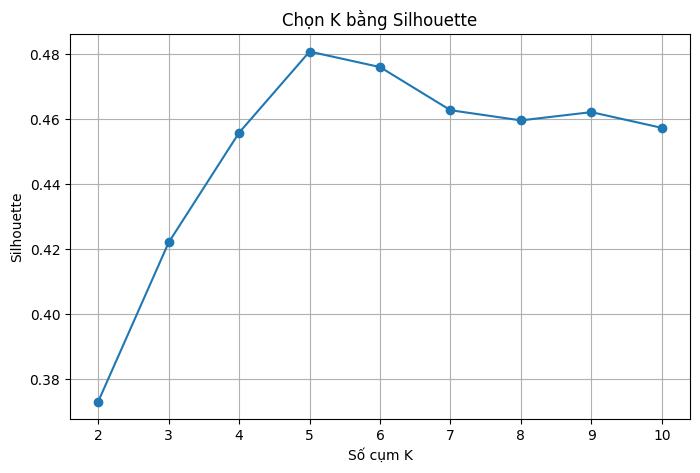

In [9]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# Đọc dữ liệu
df = pd.read_csv("data/khach_hang.csv")

# Lấy cả 3 thuộc tính
X = df[["tuoi", "thu_nhap", "diem_chi_tieu"]]

# Chuẩn hóa dữ liệu
sc = StandardScaler()
Xs = sc.fit_transform(X)

# Tính Silhouette với K từ 2 đến 10
ket_qua = []

print("K\tSilhouette")

for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=0)
    nhan = km.fit_predict(Xs)

    sil = silhouette_score(Xs, nhan)
    ket_qua.append(sil)

    print(f"{k}\t{sil:.3f}")

# Chọn K tốt nhất
k_tot_nhat = np.argmax(ket_qua) + 2

print("\nK tốt nhất:", k_tot_nhat)

# Phân cụm lại với K tốt nhất
km = KMeans(n_clusters=k_tot_nhat, n_init=10, random_state=0)
nhan = km.fit_predict(Xs)

# Đưa tâm cụm về đơn vị ban đầu
tam = pd.DataFrame(
    sc.inverse_transform(km.cluster_centers_),
    columns=["tuoi", "thu_nhap", "diem_chi_tieu"]
)

print("\nTâm các cụm:")
print(tam.round(1))

# Vẽ biểu đồ Silhouette
plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), ket_qua, marker="o")
plt.xlabel("Số cụm K")
plt.ylabel("Silhouette")
plt.title("Chọn K bằng Silhouette")
plt.xticks(range(2, 11))
plt.grid()
plt.show()

Nhận xét: K tốt nhất là giá trị có Silhouette cao nhất. Khi thêm tuổi, kết quả phân cụm và tâm cụm có thể thay đổi vì thuật toán sử dụng thêm một thuộc tính để tính khoảng cách.

Bài 3

In [10]:
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Đọc dữ liệu
df = pd.read_csv("data/khach_hang.csv")

X = df[["thu_nhap", "diem_chi_tieu"]]

# Chuẩn hóa dữ liệu
Xs = StandardScaler().fit_transform(X)

# Thử hai cách khởi tạo
for cach in ["random", "k-means++"]:

    ket_qua = []

    for rs in range(50):
        km = KMeans(
            n_clusters=5,
            init=cach,
            n_init=1,
            random_state=rs
        )

        km.fit(Xs)
        ket_qua.append(round(km.inertia_, 1))

    # Đếm số lần đạt inertia 23.0
    so_lan_tot = ket_qua.count(23.0)

    print("Cách khởi tạo:", cach)
    print("Số lần đạt inertia 23.0:", so_lan_tot)
    print("Inertia nhỏ nhất:", min(ket_qua))
    print("Inertia lớn nhất:", max(ket_qua))
    print()

Cách khởi tạo: random
Số lần đạt inertia 23.0: 30
Inertia nhỏ nhất: 23.0
Inertia lớn nhất: 204.0

Cách khởi tạo: k-means++
Số lần đạt inertia 23.0: 50
Inertia nhỏ nhất: 23.0
Inertia lớn nhất: 23.0



Nhận xét: K-Means++ thường đáng tin cậy hơn khởi tạo ngẫu nhiên vì chọn các tâm ban đầu có khoảng cách phù hợp hơn, giảm khả năng rơi vào nghiệm phân cụm kém. Dựa vào số lần đạt inertia 23.0 ở kết quả chạy để so sánh hai cách.

Bài 4

Dung lượng ảnh gốc: 551315 bytes
Dung lượng ảnh 16 màu: 155488 bytes


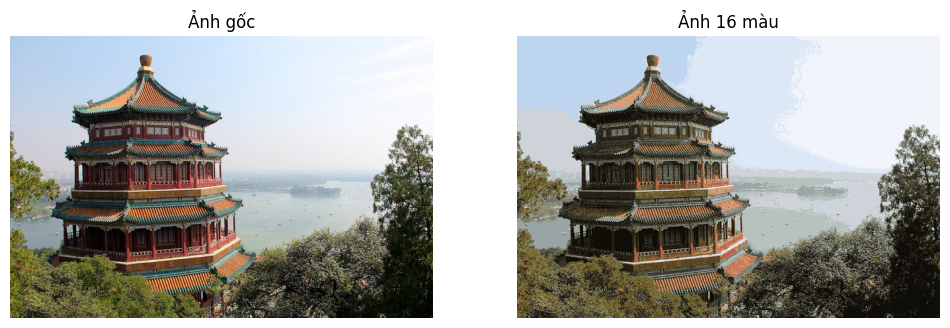

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import os

from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image

# Đọc ảnh có sẵn trong sklearn
anh = load_sample_image("china.jpg")

cao, rong, _ = anh.shape

# Chuyển ảnh thành các điểm ảnh RGB
diem = anh.reshape(-1, 3) / 255.0

# Lấy ngẫu nhiên 5000 điểm ảnh
rng = np.random.default_rng(0)
mau = diem[rng.choice(len(diem), 5000, replace=False)]

# Phân cụm thành 16 màu
km = KMeans(n_clusters=16, n_init=4, random_state=0)
km.fit(mau)

# Gán màu mới cho toàn bộ ảnh
nhan = km.predict(diem)
moi = km.cluster_centers_[nhan]

# Đưa ảnh về kích thước ban đầu
anh_moi = moi.reshape(cao, rong, 3)

# Lưu ảnh gốc và ảnh 16 màu
plt.imsave("anh_goc.png", anh)
plt.imsave("anh_16_mau.png", anh_moi)

# So sánh dung lượng
print("Dung lượng ảnh gốc:", os.path.getsize("anh_goc.png"), "bytes")
print("Dung lượng ảnh 16 màu:", os.path.getsize("anh_16_mau.png"), "bytes")

# Hiển thị hai ảnh
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(anh)
plt.title("Ảnh gốc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(anh_moi)
plt.title("Ảnh 16 màu")
plt.axis("off")

plt.show()

Saving ab67616d0000b273815ba1af3707438172f1f9ac.jpg to ab67616d0000b273815ba1af3707438172f1f9ac.jpg


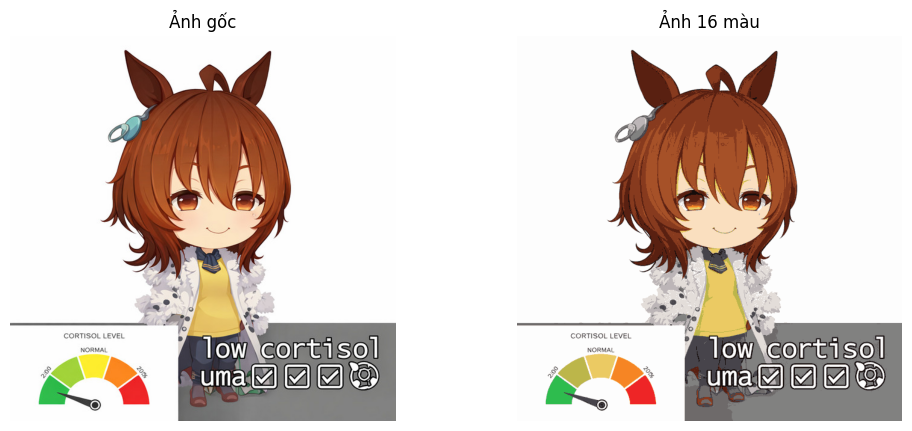

Đã lưu ảnh 16 màu cá nhân.


In [12]:
from google.colab import files

# Tải ảnh cá nhân lên
uploaded = files.upload()

# Lấy tên ảnh vừa tải
ten_anh = list(uploaded.keys())[0]

# Đọc ảnh
anh_ca_nhan = plt.imread(ten_anh)

# Bỏ kênh alpha nếu ảnh có 4 kênh
if anh_ca_nhan.ndim == 3 and anh_ca_nhan.shape[2] == 4:
    anh_ca_nhan = anh_ca_nhan[:, :, :3]

# Chuyển ảnh về dạng RGB
if anh_ca_nhan.dtype == np.uint8:
    diem = anh_ca_nhan.reshape(-1, 3) / 255.0
else:
    diem = anh_ca_nhan.reshape(-1, 3)

cao, rong, _ = anh_ca_nhan.shape

# Lấy tối đa 5000 điểm ảnh
rng = np.random.default_rng(0)
so_mau = min(5000, len(diem))
mau = diem[rng.choice(len(diem), so_mau, replace=False)]

# Phân cụm 16 màu
km = KMeans(n_clusters=16, n_init=4, random_state=0)
km.fit(mau)

nhan = km.predict(diem)
moi = km.cluster_centers_[nhan]

anh_moi = moi.reshape(cao, rong, 3)

# Lưu ảnh
plt.imsave("anh_16_mau_ca_nhan.png", anh_moi)

# Hiển thị kết quả
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(anh_ca_nhan)
plt.title("Ảnh gốc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(anh_moi)
plt.title("Ảnh 16 màu")
plt.axis("off")

plt.show()

print("Đã lưu ảnh 16 màu cá nhân.")

Nhận xét: Ảnh sau khi nén chỉ còn 16 màu nên số lượng màu giảm đáng kể. Ảnh vẫn giữ được hình dạng tổng thể nhưng một số chi tiết và màu sắc có thể thay đổi.

Bài 5

Eps: 0.2
Số cụm: 1
Số điểm nhiễu: 40


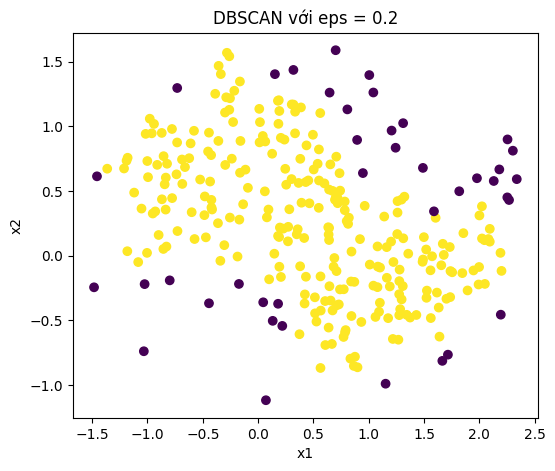

Eps: 0.3
Số cụm: 1
Số điểm nhiễu: 10


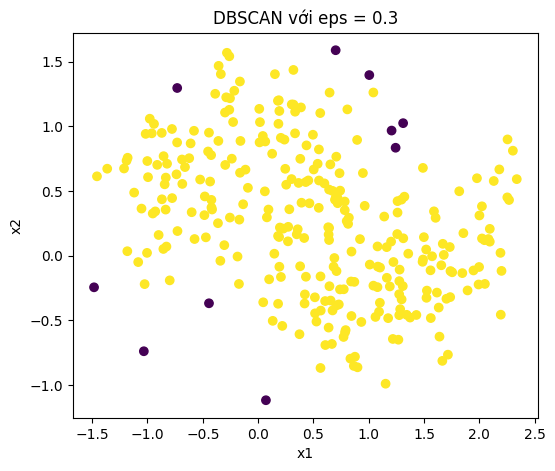

Eps: 0.4
Số cụm: 1
Số điểm nhiễu: 3


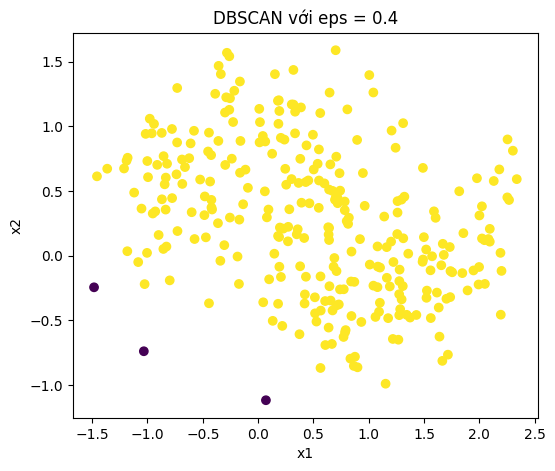

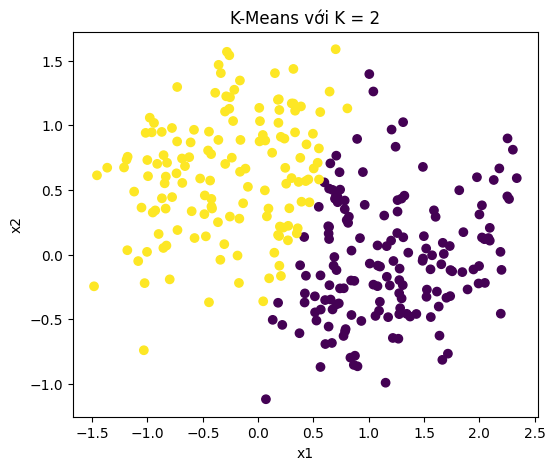

In [13]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import DBSCAN
from sklearn.cluster import KMeans

# Đọc dữ liệu hai vầng trăng
tr = pd.read_csv("data/hai_vang_trang.csv")

X = tr[["x1", "x2"]]

# Chạy DBSCAN với các giá trị eps
for e in [0.2, 0.3, 0.4]:

    db = DBSCAN(eps=e, min_samples=5)
    nhan = db.fit_predict(X)

    # Đếm số cụm, không tính nhãn -1
    so_cum = len(set(nhan)) - (1 if -1 in nhan else 0)

    # Đếm số điểm nhiễu
    so_nhieu = list(nhan).count(-1)

    print("Eps:", e)
    print("Số cụm:", so_cum)
    print("Số điểm nhiễu:", so_nhieu)

    # Vẽ kết quả
    plt.figure(figsize=(6, 5))
    plt.scatter(X["x1"], X["x2"], c=nhan, cmap="viridis")
    plt.title(f"DBSCAN với eps = {e}")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.show()

# So sánh với K-Means
km = KMeans(n_clusters=2, n_init=10, random_state=0)
nhan_km = km.fit_predict(X)

plt.figure(figsize=(6, 5))
plt.scatter(X["x1"], X["x2"], c=nhan_km, cmap="viridis")
plt.title("K-Means với K = 2")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()

Nhận xét: DBSCAN có thể phát hiện các cụm có hình dạng cong như hai vầng trăng, trong khi K-Means thường chia dữ liệu theo ranh giới gần đường thẳng. eps là bán kính lân cận: eps quá nhỏ có thể tạo nhiều điểm nhiễu, eps quá lớn có thể gộp các cụm lại với nhau.

Bài 6

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.cluster import KMeans

# Tải dữ liệu chữ số viết tay
digits = load_digits()

X = digits.data
nhan_that = digits.target

# Phân cụm K-Means với K = 10
km = KMeans(n_clusters=10, n_init=10, random_state=0)

cum = km.fit_predict(X)

# Lập bảng so sánh nhãn thật và cụm
bang = pd.crosstab(nhan_that, cum)

print("Bảng so sánh nhãn thật và cụm:")
print(bang)

# Hiển thị chữ số xuất hiện trong từng cụm
print("\nCác chữ số trong từng cụm:")

for k in range(10):
    chu_so = bang.index[bang[k] > 0].tolist()

    print(f"Cụm {k}: {chu_so}")

# Hiển thị số lượng chữ số trong từng cụm
print("\nSố lượng mẫu trong từng cụm:")
print(bang.sum(axis=0))

Bảng so sánh nhãn thật và cụm:
col_0    0    1    2   3    4    5    6    7    8    9
row_0                                                 
0      176    0    0   0    0    0    2    0    0    0
1        0  100    0  54    1    2    0    1    0   24
2        1    8    3   2   13    0    0    0    2  148
3        0    7    7   0  154    0    0    2   13    0
4        0    2   11   3    0    0  165    0    0    0
5        0    0    0   0    2    1    2  136   41    0
6        1    3    0   0    0  177    0    0    0    0
7        0    2  174   2    0    0    0    1    0    0
8        0  100    5   6    2    2    0    4   52    3
9        0    1    8  20    6    0    0    6  139    0

Các chữ số trong từng cụm:
Cụm 0: [0, 2, 6]
Cụm 1: [1, 2, 3, 4, 6, 7, 8, 9]
Cụm 2: [2, 3, 4, 7, 8, 9]
Cụm 3: [1, 2, 4, 7, 8, 9]
Cụm 4: [1, 2, 3, 5, 8, 9]
Cụm 5: [1, 5, 6, 8]
Cụm 6: [0, 4, 5]
Cụm 7: [1, 3, 5, 7, 8, 9]
Cụm 8: [2, 3, 5, 8, 9]
Cụm 9: [1, 2, 8]

Số lượng mẫu trong từng cụm:
col_0
0    178
1    2

Nhận xét: K-Means phân cụm dựa trên đặc điểm hình ảnh chứ không biết trước chữ số thật. Một cụm có thể chứa nhiều chữ số khác nhau nếu hình dạng ảnh tương tự nhau. Bảng kết quả giúp quan sát chữ số nào được gom vào cùng cụm và chữ số nào được phân tách tốt.